
# Laboratoire de programmation mathématique 1 :<br/> Introduction à Python et à ses bibliothèques mathématiques

> **Note administrative :** Ce premier TP introductoire ne dure qu'une semaine et n'est pas à rendre. Les suivants s'étaleront sur 2 ou 3 semaines et devront être déposés sur Moodle avant la date limite
## Introduction

Le but de ce cours est d'apprendre à utiliser les ordinateurs pour résoudre des problèmes mathématiques, faire des expériences mathématiques et observer des phénomènes mathématiques intéressants. Nous utiliserons le langage de programmation **Python** (avec l'environnement de programmation **Jupyter**), car il est très populaire et facile à apprendre (vous le connaissez peut-être déjà et vous le rencontrerez probablement à nouveau dans le futur).

Avant de commencer, regardons quelques exemples. Essayez de comprendre le code écrit dans les cellules (si vous ne pouvez pas le comprendre à ce stade, c'est parfaitement normal). Les lignes commençant par # sont des commentaires qui pourraient vous aider.

Cliquez dans chaque cellule et appuyez sur SHIFT+ENTER pour l'exécuter. Si cela ne fonctionne pas, demandez de l'aide.

**Exemple 1: calcul symbolique**

Cet exemple montre comment utiliser la bibliothèque `sympy` pour effectuer des calculs symboliques, tels que trouver la valeur d'une intégrale.

Trouver la valeur de $\int_{-\infty}^\infty e^{-x^2} dx$

In [12]:
# importer depuis une bibliothèque pour les calculs symboliques
from sympy import Symbol, exp, oo, integrate

# faire de x une variable sympy
x = Symbol('x')
x

x

In [14]:
integrate(exp(-x**2), (x, -oo, oo))

sqrt(pi)

**Exemple 2: marches aléatoires**

Cet exemple montre comment simuler des marches aléatoires et visualiser les résultats à l'aide de `matplotlib`.

Dessiner les graphes de 3 marches aléatoires
(on commence à la position 0 et à chaque pas on se déplace soit de 1 soit de -1; on fait 5000 pas)

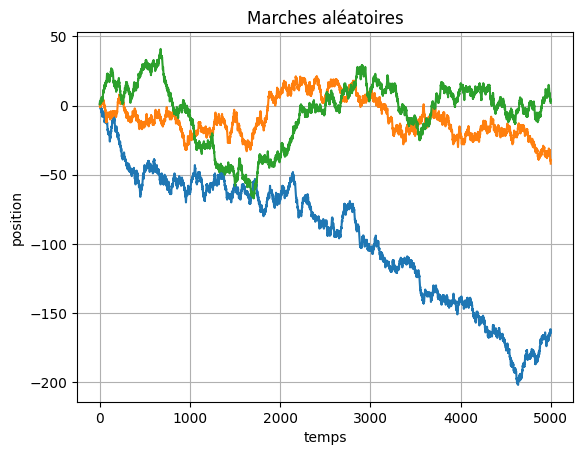

In [1]:
# importer une bibliothèque graphique et numérique

import matplotlib.pyplot as plt
import numpy as np

# répéter 3 fois
for i in range(3):
    # choisir 5000 fois au hasard soit -1 soit 1
    steps = np.random.choice([-1,1], size=5000)
    # calculer la somme walk[k] = steps +... + steps[k] pour chaque 0 ≤ k < 5000 ('somme cumulée')
    walk = np.cumsum(steps)
    # dessiner le graphique de la marche
    plt.plot(walk)

# mettre des étiquettes et une grille sur l'image
plt.title('Marches aléatoires')
plt.grid()
plt.xlabel('temps')
plt.ylabel('position')

plt.show()

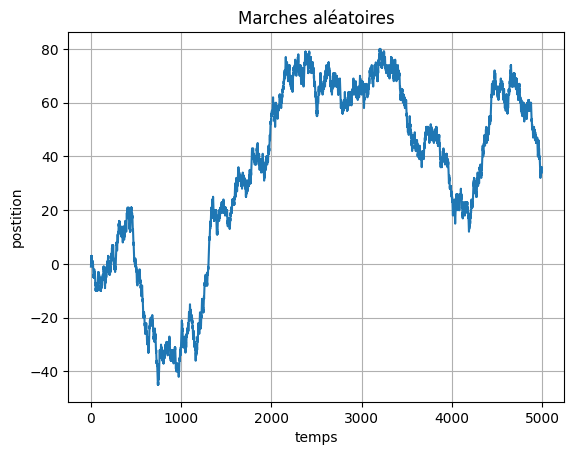

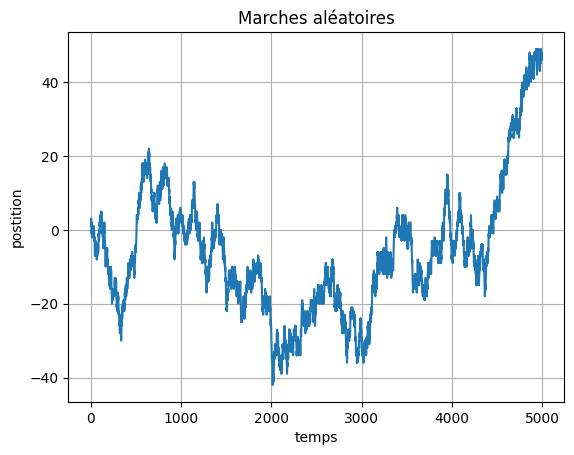

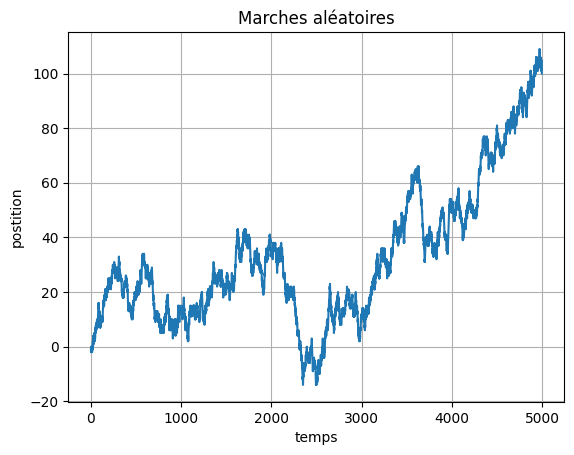

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

for i in range(3):
    steps = np.random.choice([-1,1], size=5000)
    walk = np.cumsum(steps)
    plt.plot(walk)

    plt.title("Marches aléatoires")
    plt.grid()
    plt.xlabel('temps')
    plt.ylabel('postition')

    plt.show()

Si vous connaissez un peu python, vous avez remarqué que nous utilisions des bibliothèques. Nous rencontrerons les bibliothèques suivantes dans notre cours:

- **sympy** pour les calculs symboliques (par exemple: résoudre vos devoirs d'algèbre ou d'analyse)
- **numpy** pour les calculs numériques rapides (par exemple: inverser une matrice 10000 x 10000)
- **scipy** pour des algorithmes numériques plus avancés (par exemple: résoudre numériquement une équation différentielle)
- **matplotlib** pour le traçage
- **numba** pour compiler fonctions en code machine

## Premiers pas avec python: l'algorithme d'Euclide pour calculer le plus grand diviseur commun

Notre objectif est d'écrire une fonction python `gcd` calculant le plus grand diviseur commun de deux entiers et d'apprendre quelques bases de python en cours de route.\
**Si vous connaissez déjà les bases de python, vous pouvez aller à la fin de cette section et écrire et tester la fonction `gcd`.**

Commençons par une fonction simple qui multiplie par deux. Les fonctions sont définies par le mot-clé `def`. Cliquez sur la cellule suivante et appuyez sur SHIFT+ENTER pour l'exécuter.

In [ ]:
def double(n):
    return 2*n

Tapez `double(10)` dans la cellule ci-dessous et exécutez-la. Quelle surprise!

In [ ]:
double(10)

Voici une fonction qui affiche les n premières puissances de 2 ($2^k$ peut être calculé directement via `2**k`). Il contient une boucle (`for`), où i va de 0 à n-1. Essayez la fonction. (Cette fonction ne renvoie rien, elle affiche juste du texte.)

In [1]:
def powers_of_2(n):
    power = 1
    for i in range(n):
        power = power * 2
        print(power)
    print("et c'est tout")


In [9]:
def powers_of_two(n):
    power = 1
    for i in range(n):
        power = power *2
        print(power)
    print("Et c'est tout")

powers_of_two(4)

2
4
8
16
Et c'est tout


In [10]:
def powers_of_two_list(n):
    power = 1
    out = []
    for _ in range(n):
        power *=2
        out.append(power)
    return out

print(powers_of_two_list(4))

[2, 4, 8, 16]


<div style="border: 1px solid gold; padding: 5px">

**Exercice:** Modifier la fonction `powers_of_2`:

- remplacer `print(power)` par `print(f'2^{i+1} = {power}')` - si on met `f` devant une chaîne, chaque `{expr}` à l'intérieur de la chaîne est remplacé par la valeur de `expr`, ce qui est une jolie petite astuce python
- remplacer la boucle `for` par une boucle `while`:
    ```python
    i = 0
    while i < n:
        ...
        i = i + 1 # ou plus brièvement: i += 1
    ```
</div>

>Vous pouvez ajouter plus de cellules au-dessus ou au-dessous si vous en avez besoin - il y a un bouton + dans le menu.

Essayez les fonctions suivantes pour voir ce qu'elles font. (En python, pour vérifier si a et b sont égaux, on utilise `a == b` (puisque `a = b` est déjà utilisé).)\
Astuce: écrivez juste le début du nom d'une fonction, disons `orde`, et appuyez sur TAB.

In [ ]:
def triangle(n):
    for i in range(1, n + 1):
        print(i * 'o')

def order_them(a, b):
    if a > b:
        a, b = b, a
    return a, b

def is_even(n):
    # n%2 est le reste de n modulo 2
    if n%2 == 0:
        print(f'{n} est pair')
    else:
        print(f'{n} est impair')

<div style="border: 1px solid gold; padding: 5px">

**Exercice:**

Enfin, écrivez la fonction `gcd(a, b)` en utilisant une boucle `while` et l'algorithme d'Euclide.
Le reste de `a` modulo `b` est en python noté `a % b`.
</div>

In [ ]:
### ÉCRIVEZ ICI
def gdc(a, b):
    while 

Testez votre fonction (vérifiez si les résultats sont vrais!):

In [ ]:
for a, b in [(10, 12), (12, 10), (-35, 91), (-8, -8)]:
    print(f'gcd({a}, {b}) = {gcd(a, b)}')

## Conjecture de Collatz

Commençons par un entier strictement positif n. S'il est pair, divisez-le par 2, s'il est impair, remplacez-le par 3n+1.
La conjecture de Collatz dit qu'on atteint toujours 1. Elle est connue pour être vraie pour tout $n\leq 10^{20}$, mais pour un n général, c'est un problème ouvert.

Voici un exemple:
$$7\to 22\to 11\to 34 \to 17\to 52\to 26\to 13\to 40\to 20\to 10\to 5\to 16\to 8\to 4\to 2\to 1$$

<div style="border: 1px solid gold; padding: 5px">

**Exercice:**

- Écrire une fonction `collatz_seq(n)` qui affiche tous les nombres de la séquence résultante.
  Conseils Python:
  - pour diviser n par 2 il vaut mieux utiliser `n//2` (division entière) que `n/2`; cela garantit que le résultat est un entier
  - essayez `print(n, end=', ')` au lieu de `print(n)` pour économiser de l'espace
- Une fois que cela fonctionne, écrivez une fonction `collatz(n)` qui renvoie la longueur de la séquence.
</div>

In [ ]:
### ÉCRIVEZ ICI


Testez votre fonction:

In [ ]:
assert collatz(7) == 16, 'expected 16'

affichez `collatz(n)` pour les n jusqu'à 50 - il semble y avoir d'étranges répétitions (voir par exemple les trois 16 consécutifs vers la fin):

Pour en voir plus, dessinons un graphique - mais d'abord, nous devons apprendre à le faire en python.

## Tracé

### Listes

Une liste en python (souvent appelée tableau dans d'autres langages de programmation) est une séquence d'objets, telle que [2, 5, 1, 7]. Essayez les cellules suivantes pour voir ce que nous pouvons en faire.

In [ ]:
lst = [3, 'abc', 9, [8, 3], 10/11, 5]

for item in lst:
    print(item)

print()

print(lst[0], lst[1], lst[-1])

lst[2] = 'new'

print(lst[1:4])

lst.append('more')
print(lst)

Un peu plus sur les méthodes de créer des listes:

In [ ]:
lst1 = [i**2 for i in range(10)]

lst2 = []
for i in range(10):
    lst2.append(i**2)

print(lst1)
print(lst2)

### Tracé d'une liste avec matplotlib

Nous importons d'abord la bibliothèque de traçage. Explication: on importe matplotlib.pyplot et on le renomme en plt. Toutes les fonctions fournies par la bibliothèque sont alors accessibles comme `plt.nom_d_une_fonction`).

In [ ]:
import matplotlib.pyplot as plt

Si nous avons une liste de nombres, nous pouvons maintenant la tracer.

In [ ]:
lst = [i**2 for i in range(10)]

plt.plot(lst)
plt.show()

Si nous voulons voir juste des points, nous pouvons le faire comme suit:

In [ ]:
plt.plot(lst, '.')
plt.show()

Si nous avons deux listes, l'une avec des valeurs x et l'autre avec des valeurs y, nous pouvons également tracer la courbe résultante.

In [ ]:
x = [n/100 for n in range(100)]
y = [z**2 for z in x]

plt.plot(x, y)
plt.show()

### Tracé des valeurs `collatz(n)`

<div style="border: 1px solid gold; padding: 5px">

**Exercice:**

- Créez une liste contenant les valeurs `collatz(n)` pour n de 1 à 100.
- Tracez la liste. Utilisez l'option de tracé '.' pour rendre le tracé plus utile (vous pouvez également diminuer la taille des points en incluant l'option `markersize=1`). Essayez ensuite avec une liste de `collatz(n)` pour tous les $n\leq10000$.
</div>

In [ ]:
# ÉCRIVEZ ICI


Quel comportement étrange! Aucune explication n'est connue.

<div style="border: 1px solid gold; padding: 5px">

Parfois, lorsque de grands nombres sont impliqués (comme sur notre axe des x), il est préférable d'utiliser une échelle logarithmique (dans notre cas, comme vous le verrez, elle remplace certaines courbes par des droites approximativement). Copier votre cellule précédente dessous et, pour obtenir l'échelle logarithmique sur l'axe $x$,  ajoutez la commande `plt.xscale('log')` au-dessus de la commande `plt.show()` . Vous pouvez augmenter la limite supérieure de 10000 à un nombre plus grand (il y a un bouton interrompre le noyau dans le menu, au cas où vous voudriez arrêter le calcul).
</div>

In [ ]:
# ÉCRIVEZ ICI


> Une petite remarque technique à propos des entiers en python: contrairement à la plupart des langages de programmation, ils peuvent être arbitrairement grands (tant qu'ils tiennent dans la mémoire de l'ordinateur). Nous n'avons donc pas eu à nous soucier des débordements dans les suites de Collatz.

### Plus de tracés: un peu de numpy

Le tracé fonctionne particulièrement bien avec la bibliothèque numérique python numpy. Cette bibliothèque fournit des tableaux numpy, qui sont comme des listes python, mais ne contiennent que des nombres. Le principal avantage est que nous pouvons facilement calculer avec eux (et le calcul est vraiment rapide, même pour des tableaux énormes). Essayez la cellule suivante pour voir comment cela fonctionne.

In [ ]:
# importer la bibliothèque et l'appeler np; tout objet importé sera accessible comme np.nom_de_l_objet
import numpy as np

# créer deux tableaux de même longueur
a = np.array([2, 7, 3, 3.1415])
b = np.array([0, -15, np.e, - np.pi])
print('a = ', a)
print('b = ', b)

# comment calculer avec des tableaux:
print('a + b =', a + b)
print('a * b =', a * b)
print('a**2 - 4 * a * b =', a**2 - 4 * a * b)

print()
# les tableaux peuvent avoir plusieurs dimensions (2 dans l'exemple suivant):
c = np.array([[0, 1, 2], [3, 4, 5], [6, 7, 8]])
print(c)
print(c**2)

print()
# un tableau numpy particulièrement utile: np.linspace(x, y, n) donne n nombres équidistants dans l'intervalle [x,y]:
print(np.linspace(0, 1, 6))

Traçons maintenant les graphes de deux fonctions, en utilisant des tableaux plutôt que des listes

In [ ]:
import numpy as np

# créer un tableau numpy de 0 à 2, avec 1000 points de données
x = np.linspace(0, 2, 1000)

# le début de x ressemble à ceci
print('x commence par', x[:10])

# c'est la puissance des tableaux numpy: on peut calculer un nouveau tableau y à partir de x en utilisant une formule!
y = x**3 - 2*x + 1
print('y commence par', y[:10])

# label = '...' est utilisé pour distinguer les deux graphiques (il est composé avec la commande plt.legend() ci-dessous)
plt.plot(x, y, label='$x^3 - 2x - 1$')

# r'...' (r signifie 'raw') signifie que les \' dans la chaîne sont pris tels qu'ils sont écrits
# $...$ indique à matplotlib d'interpréter la chaîne comme du latex (ne vous inquiétez pas si cela n'a pas de sens pour vous)
plt.plot(x, x * np.cos(x/2), label=r'$x\, \cos(x)$')

plt.legend()
plt.show()

<div style="border: 1px solid gold; padding: 5px">

**Exercice:**

Dessinez les courbes
$$x = \sin t,\quad y = \cos t \qquad t\in[0,2\pi]$$
et
$$x = \sin t,\quad y = \cos^3 t - \frac12\cos t\qquad t\in[0,2\pi]$$
(vous pouvez obtenir $\pi$ via `np.pi`).
</div>

> Remarque: les courbes peuvent paraître un peu étranges, car les axes x et y n'ont pas la même échelle. Corrigez-le avec la commande `plt.axis('scaled')` (juste avant `plt.show()`). Vous pouvez aussi utiliser la méthode de tracé plus explicite suivante
> ```python
> ax = plt.axes() # cela crée une nouvelle "zone de dessin" et l'appelle ax
> ax.plot(x, y) # dessiner sur ax
> ax.set_aspect(1) # fait en sorte que les axes aient la même échelle
> ```

In [ ]:
### ÉCRIVEZ ICI


### Tracé de fonctions à deux variables

Supposons que nous voulions visualiser une fonction de deux variables, disons
$$f(x,y)=3 xy^2-x^3\qquad (x,y)\in[-1,1]^2.$$
Pour ce faire avec matplotlib, nous devons d'abord calculer les valeurs de $f$: nous allons créer un tableau à 2 dimensions z de taille $1000\times 1000$ contenant les valeurs de $f$ dans le carré $[-1,1]^2$.

In [ ]:
def f(x, y):
    return 3 * x * y**2 - x**3

x = np.linspace(-1, 1, 1000)
y = np.linspace(-1, 1, 1000)
x, y = np.meshgrid(x, y)
# x et y sont maintenant des tableaux à 2 dimensions de taille 1000×1000: voir ci-dessous

z = f(x, y)

# pour comprendre ce qui s'est passé, voici des parties des tableaux 2D:
print('x:')
print(x[:4,:4])
print('y:')
print(y[:4,:4])
print('z:')
print(z[:4,:4])

Nous pouvons ensuite visualiser la fonction en 2 dimensions en utilisant des couleurs ou en utilisant ses courbes de niveau (contours). C'est souvent plus utile que le graphe de la fonction.

In [ ]:
# 10 est le nombre de contours
plt.contour(x, y, z, 10)
plt.axis('scaled')
plt.show()

# if you don't need a colorbar, just write plt.contourf(x, y, z, 10)
cs = plt.contourf(x, y, z, 10)
plt.colorbar(cs)
plt.axis('scaled')
plt.show()

Cependant, si nous voulons voir le graphe (ou toute surface paramétrée), matplotlib peut le faire pour nous. Notez que nous créons maintenant une "zone de dessin" ax via `ax = plt.axes(projection='3d')` - cela la rend tridimensionnelle.

> Remarque: La cellule commence par la "commande magique `%matplotlib widget`, qui indique à jupyter ((notre environnement de programmation) d'afficher des graphiques interactifs. Vous pouvez faire pivoter le graphique avec votre souris, ce qui est très utile en 3 dimensions! (Sans cela, vous obtiendriez juste une image non interactive.)
> Pour revenir aux images non interactives, utilisez `%matplotlib inline`.
>
> <span style="color:purple">Si vous rencontrez des problèmes, ajoutez la ligne `plt.close()` au début de la cellule (cela "ferme" la figure précédente).</span>

> Autre remarque: Si vous exécutez ceci dans **google colab**, supprimez la ligne `%matplotlib widget` - cela ne fonctionne pas là-bas.



>

In [ ]:

# supprimer ceci si cela cause des problèmes (vous perdrez l'interactivité)
%matplotlib widget

# décommenter si besoin:
# plt.close()

ax = plt.axes(projection='3d')
ax.plot_wireframe(x, y, z)
plt.show()

<div style="border: 1px solid gold; padding: 5px">

**Exercice:**

Tracez la surface paramétrée par $(s,t)\in[-1,1]^2$
$$x = st,\quad y=s^2-t^2,\quad z=s$$
en utilisant la commande `ax.plot_wireframe(x, y, z)`.
</div>

In [ ]:
### ÉCRIVEZ ICI


Enfin, voici comment tracer une courbe en 3d: utilisez simplement `ax.plot`. Ici, c'est montré pour une hélice - essayez votre propre courbe!

In [ ]:
t = np.linspace(0, 6 * np.pi, 1000)

x = np.cos(t)
y = np.sin(t)
z = t

plt.close()

ax = plt.axes(projection='3d')
ax.plot(x, y, z)
plt.show()